In [11]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
from langgraph.checkpoint.memory import InMemorySaver

load_dotenv()

llm = ChatGoogleGenerativeAI(
    model="gemini-3.1-flash-lite",
    temperature=0.7
)

class JokeState(TypedDict):

    topic: str
    joke: str
    explanation: str

In [4]:
def generate_joke(state: JokeState):

    prompt = f'generate a joke on the topic {state["topic"]}'
    response = llm.invoke(prompt).content

    return {'joke': response}

In [7]:
def generate_explanation(state: JokeState):

    prompt = f'write an explanation for the joke - {state["joke"]}'
    response = llm.invoke(prompt).content

    return {'explanation': response}

In [8]:
graph = StateGraph(JokeState)

graph.add_node('generate_joke', generate_joke)
graph.add_node('generate_explanation', generate_explanation)

graph.add_edge(START, 'generate_joke')
graph.add_edge('generate_joke', 'generate_explanation')
graph.add_edge('generate_explanation', END)

checkpointer = InMemorySaver()

workflow = graph.compile(checkpointer=checkpointer)

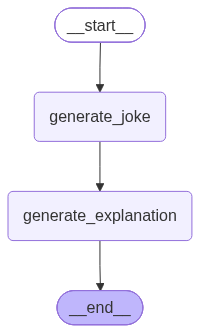

In [9]:
workflow

In [12]:
config1 = {"configurable": {"thread_id": "1"}}
workflow.invoke({'topic':'Football'}, config=config1)

{'topic': 'Football',
 'joke': [{'type': 'text',
   'text': 'Why did the football coach go to the bank?\n\nBecause he wanted to get his **quarterback**!',
   'extras': {'signature': 'EnMKcQFpFH0T5/Id4kbNedP32xQ+iLjPlw34s06xsGg/ONTgNCG+LkRHC6s0gqSweZuTgYuf3FpkMI2HBHVskwv0JXYq/Na+x2TOs8GO/Lejcp676tzuN2MyPQt4tFH8sDRg0pHYlnzQ8+pjF58ZIOA5uwI5'}}],
 'explanation': [{'type': 'text',
   'text': 'This joke is a play on words based on the double meaning of the word **"quarterback."**\n\nHere is the breakdown:\n\n1.  **In Football:** The "quarterback" is the most important player on the team, responsible for leading the offense and throwing the ball.\n2.  **In Banking:** A "quarter" is a coin worth 25 cents. If you go to a bank, you might want to exchange a larger bill (like a dollar) for smaller coins—specifically, four "quarters." Therefore, if you are asking for your money back in coins, you are literally asking for your **"quarter back."**\n\n**The humor:** The joke relies on the fact that th

In [ ]:
# You can see below different state is saved/persisted in different threads
workflow.get_state(config1)

StateSnapshot(values={'topic': 'Football', 'joke': [{'type': 'text', 'text': 'Why did the football coach go to the bank?\n\nBecause he wanted to get his **quarterback**!', 'extras': {'signature': 'EnMKcQFpFH0T5/Id4kbNedP32xQ+iLjPlw34s06xsGg/ONTgNCG+LkRHC6s0gqSweZuTgYuf3FpkMI2HBHVskwv0JXYq/Na+x2TOs8GO/Lejcp676tzuN2MyPQt4tFH8sDRg0pHYlnzQ8+pjF58ZIOA5uwI5'}}], 'explanation': [{'type': 'text', 'text': 'This joke is a play on words based on the double meaning of the word **"quarterback."**\n\nHere is the breakdown:\n\n1.  **In Football:** The "quarterback" is the most important player on the team, responsible for leading the offense and throwing the ball.\n2.  **In Banking:** A "quarter" is a coin worth 25 cents. If you go to a bank, you might want to exchange a larger bill (like a dollar) for smaller coins—specifically, four "quarters." Therefore, if you are asking for your money back in coins, you are literally asking for your **"quarter back."**\n\n**The humor:** The joke relies on the fa

In [15]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'Football', 'joke': [{'type': 'text', 'text': 'Why did the football coach go to the bank?\n\nBecause he wanted to get his **quarterback**!', 'extras': {'signature': 'EnMKcQFpFH0T5/Id4kbNedP32xQ+iLjPlw34s06xsGg/ONTgNCG+LkRHC6s0gqSweZuTgYuf3FpkMI2HBHVskwv0JXYq/Na+x2TOs8GO/Lejcp676tzuN2MyPQt4tFH8sDRg0pHYlnzQ8+pjF58ZIOA5uwI5'}}], 'explanation': [{'type': 'text', 'text': 'This joke is a play on words based on the double meaning of the word **"quarterback."**\n\nHere is the breakdown:\n\n1.  **In Football:** The "quarterback" is the most important player on the team, responsible for leading the offense and throwing the ball.\n2.  **In Banking:** A "quarter" is a coin worth 25 cents. If you go to a bank, you might want to exchange a larger bill (like a dollar) for smaller coins—specifically, four "quarters." Therefore, if you are asking for your money back in coins, you are literally asking for your **"quarter back."**\n\n**The humor:** The joke relies on the f

In [16]:
config2 = {"configurable": {"thread_id": "2"}}
workflow.invoke({'topic':'Cricket'}, config=config2)

{'topic': 'Cricket',
 'joke': [{'type': 'text',
   'text': 'Why is it so hard to play cricket in the jungle?\n\nBecause there are too many **cheetahs**!',
   'extras': {'signature': 'EnMKcQFpFH0Tv9SwAU0LxALMrxFP1VOMmXDhyb5WKrXGlUGTKsg4X11Kc/fLFtRV5NfavWYmicA8VeKsDhzq/DIzUizfSNIymJcfwDa7ZbcMUrhEXfxcVkB0ug5/ELo2LM9vcF4ixzmH3KQxB4VkxeJKp4BU'}}],
 'explanation': [{'type': 'text',
   'text': 'This joke relies on a **pun**—a play on words that sound the same but have different meanings.\n\nHere is the breakdown:\n\n1.  **The Context:** The joke sets up a scenario about playing cricket in the "jungle." In a jungle, you would naturally expect to find wild animals, specifically **cheetahs** (the fast-running big cats).\n2.  **The Pun:** The word "cheetahs" sounds exactly like the word **"cheaters"** (people who play unfairly or break the rules).\n3.  **The Punchline:** In sports, you cannot have a fair game if there are "cheaters" involved. By using the animal name "cheetahs," the joke creates 

In [17]:
workflow.get_state(config2)

StateSnapshot(values={'topic': 'Cricket', 'joke': [{'type': 'text', 'text': 'Why is it so hard to play cricket in the jungle?\n\nBecause there are too many **cheetahs**!', 'extras': {'signature': 'EnMKcQFpFH0Tv9SwAU0LxALMrxFP1VOMmXDhyb5WKrXGlUGTKsg4X11Kc/fLFtRV5NfavWYmicA8VeKsDhzq/DIzUizfSNIymJcfwDa7ZbcMUrhEXfxcVkB0ug5/ELo2LM9vcF4ixzmH3KQxB4VkxeJKp4BU'}}], 'explanation': [{'type': 'text', 'text': 'This joke relies on a **pun**—a play on words that sound the same but have different meanings.\n\nHere is the breakdown:\n\n1.  **The Context:** The joke sets up a scenario about playing cricket in the "jungle." In a jungle, you would naturally expect to find wild animals, specifically **cheetahs** (the fast-running big cats).\n2.  **The Pun:** The word "cheetahs" sounds exactly like the word **"cheaters"** (people who play unfairly or break the rules).\n3.  **The Punchline:** In sports, you cannot have a fair game if there are "cheaters" involved. By using the animal name "cheetahs," the jok

In [18]:
list(workflow.get_state_history(config2))

[StateSnapshot(values={'topic': 'Cricket', 'joke': [{'type': 'text', 'text': 'Why is it so hard to play cricket in the jungle?\n\nBecause there are too many **cheetahs**!', 'extras': {'signature': 'EnMKcQFpFH0Tv9SwAU0LxALMrxFP1VOMmXDhyb5WKrXGlUGTKsg4X11Kc/fLFtRV5NfavWYmicA8VeKsDhzq/DIzUizfSNIymJcfwDa7ZbcMUrhEXfxcVkB0ug5/ELo2LM9vcF4ixzmH3KQxB4VkxeJKp4BU'}}], 'explanation': [{'type': 'text', 'text': 'This joke relies on a **pun**—a play on words that sound the same but have different meanings.\n\nHere is the breakdown:\n\n1.  **The Context:** The joke sets up a scenario about playing cricket in the "jungle." In a jungle, you would naturally expect to find wild animals, specifically **cheetahs** (the fast-running big cats).\n2.  **The Pun:** The word "cheetahs" sounds exactly like the word **"cheaters"** (people who play unfairly or break the rules).\n3.  **The Punchline:** In sports, you cannot have a fair game if there are "cheaters" involved. By using the animal name "cheetahs," the jo

In [33]:
# useful for debugging to see each and every node execution 
workflow.get_state({"configurable": {"thread_id": "2", "checkpoint_id": "1f15d969-8ed6-683c-8000-0c7a2f030ccd"}})

StateSnapshot(values={}, next=(), config={'configurable': {'thread_id': '2', 'checkpoint_id': '1f15d969-8ed6-683c-8000-0c7a2f030ccd'}}, metadata=None, created_at=None, parent_config=None, tasks=(), interrupts=())

In [22]:
workflow.update_state({"configurable": {"thread_id": "2", "checkpoint_id": "1f15d969-8ed6-683c-8000-0c7a2f030ccd", "checkpoint_ns": ""}}, {'topic':'Tenis'})

{'configurable': {'thread_id': '2',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1cedb5-7ac6-6c56-8000-91fe15903669'}}

In [23]:
list(workflow.get_state_history(config2))

[StateSnapshot(values={'topic': 'Tenis'}, next=('generate_joke',), config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1cedb5-7ac6-6c56-8000-91fe15903669'}}, metadata={'source': 'update', 'step': 0, 'parents': {}}, created_at='2026-10-23T12:14:48.927338+00:00', parent_config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f15d969-8ed6-683c-8000-0c7a2f030ccd'}}, tasks=(PregelTask(id='1f265f57-95df-7fc9-f629-f4c8c8a84bd5', name='generate_joke', path=('__pregel_pull', 'generate_joke'), error=None, interrupts=(), state=None, result=None),), interrupts=()),
 StateSnapshot(values={'topic': 'Cricket', 'joke': [{'type': 'text', 'text': 'Why is it so hard to play cricket in the jungle?\n\nBecause there are too many **cheetahs**!', 'extras': {'signature': 'EnMKcQFpFH0Tv9SwAU0LxALMrxFP1VOMmXDhyb5WKrXGlUGTKsg4X11Kc/fLFtRV5NfavWYmicA8VeKsDhzq/DIzUizfSNIymJcfwDa7ZbcMUrhEXfxcVkB0ug5/ELo2LM9vcF4ixzmH3KQxB4VkxeJKp4BU'}}], 'explanation': [{'typ

## Fault Tolerance

In [25]:
from langgraph.graph import StateGraph, END
from langgraph.checkpoint.memory import InMemorySaver
from typing import TypedDict
import time

# 1. Define the state
class CrashState(TypedDict):
    input: str
    step1: str
    step2: str


In [26]:
# 2. Define steps
def step_1(state: CrashState) -> CrashState:
    print("✅ Step 1 executed")
    return {"step1": "done", "input": state["input"]}

def step_2(state: CrashState) -> CrashState:
    print("⏳ Step 2 hanging... now manually interrupt from the notebook toolbar (STOP button)")
    time.sleep(30)  # Simulate long-running hang
    return {"step2": "done"}

def step_3(state: CrashState) -> CrashState:
    print("✅ Step 3 executed")
    return {"done": True}

In [27]:
# 3. Build the graph
builder = StateGraph(CrashState)
builder.add_node("step_1", step_1)
builder.add_node("step_2", step_2)
builder.add_node("step_3", step_3)

builder.set_entry_point("step_1")
builder.add_edge("step_1", "step_2")
builder.add_edge("step_2", "step_3")
builder.add_edge("step_3", END)

checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

In [28]:
try:
    print("▶️ Running graph: Please manually interrupt during Step 2...")
    graph.invoke({"input": "start"}, config={"configurable": {"thread_id": 'thread-1'}})
except KeyboardInterrupt:
    print("❌ Kernel manually interrupted (crash simulated).")


▶️ Running graph: Please manually interrupt during Step 2...
✅ Step 1 executed
⏳ Step 2 hanging... now manually interrupt from the notebook toolbar (STOP button)
❌ Kernel manually interrupted (crash simulated).


In [32]:


# 6. Re-run to show fault-tolerant resume
print("\n🔁 Re-running the graph to demonstrate fault tolerance...")
final_state = graph.invoke(None, config={"configurable": {"thread_id": 'thread-1'}})
print("\n✅ Final State:", final_state)




🔁 Re-running the graph to demonstrate fault tolerance...
⏳ Step 2 hanging... now manually interrupt from the notebook toolbar (STOP button)
✅ Step 3 executed

✅ Final State: {'input': 'start', 'step1': 'done', 'step2': 'done'}


In [31]:
list(graph.get_state_history({"configurable": {"thread_id": 'thread-1'}}))

[StateSnapshot(values={'input': 'start', 'step1': 'done'}, next=('step_2',), config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1cedbb-c6ff-623e-8001-5fe205564016'}}, metadata={'source': 'loop', 'step': 1, 'parents': {}}, created_at='2026-10-23T12:17:37.980875+00:00', parent_config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1cedbb-c6fd-6cd6-8000-b80cf7b1c789'}}, tasks=(PregelTask(id='0c8a8977-fe5c-5743-093f-57312782256b', name='step_2', path=('__pregel_pull', 'step_2'), error=None, interrupts=(), state=None, result=None),), interrupts=()),
 StateSnapshot(values={'input': 'start'}, next=('step_1',), config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1cedbb-c6fd-6cd6-8000-b80cf7b1c789'}}, metadata={'source': 'loop', 'step': 0, 'parents': {}}, created_at='2026-10-23T12:17:37.980329+00:00', parent_config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'ch